# Part A: Setup and Inspect the Dataset
Load Spambase archive, extract features, and apply fixed curation rules to remove exact duplicates and ambiguous rows.

In [5]:
from io import BytesIO
from pathlib import Path
from urllib.request import urlretrieve
from zipfile import ZipFile

import numpy as np
import pandas as pd

RANDOM_STATE = 42

### Setup Directories (Paths modified for notebook running inside week10)

In [6]:
DATA_DIR = Path("data")
REPORTS_DIR = Path("reports")
FIGURES_DIR = Path("figures")
MODELS_DIR = Path("models")

for folder in [DATA_DIR, REPORTS_DIR, FIGURES_DIR, MODELS_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

### Download and Load Data

In [7]:
archive_path = DATA_DIR / "spambase.zip"
if not archive_path.exists():
    urlretrieve(
        "https://archive.ics.uci.edu/static/public/94/spambase.zip",
        archive_path,
    )

with ZipFile(archive_path) as archive:
    names_text = archive.read("spambase.names").decode("utf-8")
    FEATURES = [line.split(":")[0] for line in names_text.splitlines() 
                if line.startswith(("word_freq_", "char_freq_", "capital_run_length_"))]
    data = pd.read_csv(BytesIO(archive.read("spambase.data")), header=None)
    data.columns = FEATURES + ["is_spam"]

### Curation Rules

In [8]:
exact_duplicates = int(data.duplicated().sum())
clean = data.drop_duplicates().copy()
ambiguous = clean.duplicated(subset=FEATURES, keep=False)

print("Exact duplicate rows removed:", exact_duplicates)
print("Ambiguous feature rows excluded:", int(ambiguous.sum()))

clean = clean.loc[~ambiguous].reset_index(drop=True)
X = clean[FEATURES].copy()
y = clean["is_spam"].astype(int) # 0 = legitimate, 1 = spam

print("Usable feature matrix:", X.shape)
print("Class counts:", y.value_counts().sort_index().to_dict())

Exact duplicate rows removed: 391
Ambiguous feature rows excluded: 6
Usable feature matrix: (4204, 57)
Class counts: {0: 2528, 1: 1676}


# Part B: Shared Split and Pipelines
Split data into Development and Test sets. Create preprocessing pipelines to prevent data leakage during cross-validation.

In [9]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier


### 75/25 Split

In [10]:
X_dev, X_test, y_dev, y_test = train_test_split(
    X, y, test_size=0.25, random_state=RANDOM_STATE, stratify=y
)

print("Development:", X_dev.shape, y_dev.value_counts().to_dict())
print("Final test:", X_test.shape, y_test.value_counts().to_dict())

Development: (3153, 57) {0: 1896, 1: 1257}
Final test: (1051, 57) {0: 632, 1: 419}


### Define Models and Pipelines

In [11]:
models = {
    "Decision Tree": DecisionTreeClassifier(max_depth=4, random_state=RANDOM_STATE),
    "k-NN": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)),
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
    "Gaussian NB": GaussianNB(),
    "Majority baseline": DummyClassifier(strategy="most_frequent"),
}

# Part C: Validate and Compare
Use 5-fold Stratified Cross-Validation on the development set to calculate accuracy, precision, recall, and F1 score.

In [12]:
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    make_scorer,
    precision_score,
    recall_score,
)
from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
folds = list(cv.split(X_dev, y_dev))

scoring = {
    "accuracy": "accuracy",
    "precision": make_scorer(precision_score, zero_division=0),
    "recall": make_scorer(recall_score, zero_division=0),
    "f1": make_scorer(f1_score, zero_division=0),
}

results = []
for name, candidate in models.items():
    scores = cross_validate(candidate, X_dev, y_dev, cv=folds, scoring=scoring)
    row = {"model": name}
    for metric in scoring:
        values = scores[f"test_{metric}"]
        row[metric] = values.mean()
        row[f"{metric}_std"] = values.std(ddof=1)
    results.append(row)

comparison = pd.DataFrame(results).sort_values(
    ["f1", "model"], ascending=[False, True]
).reset_index(drop=True)

comparison.to_csv(REPORTS_DIR / "model_comparison.csv", index=False)
display(comparison.round(3))

,model,accuracy,accuracy_std,precision,precision_std,recall,recall_std,f1,f1_std
0,Logistic Regression,0.923,0.007,0.920,0.017,0.884,0.010,0.901,0.008
1,Decision Tree,0.893,0.015,0.912,0.039,0.811,0.009,0.858,0.017
2,k-NN,0.890,0.022,0.886,0.032,0.831,0.028,0.858,0.029
3,Gaussian NB,0.826,0.020,0.712,0.026,0.951,0.013,0.814,0.017
4,Majority baseline,0.601,0.001,0.000,0.000,0.000,0.000,0.000,0.000


# Part D: Select and Evaluate Once
Visualize the CV results, select the best model based on F1 score, refit it on the entire development set, and evaluate on the final test set.

In [13]:
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.metrics import confusion_matrix

### D1. Visualize

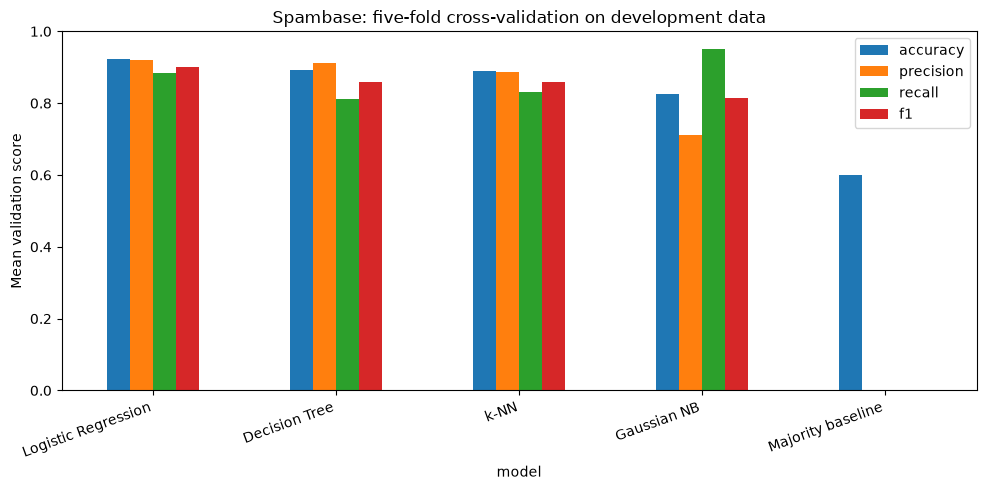

In [14]:
metrics = ["accuracy", "precision", "recall", "f1"]
ax = comparison.set_index("model")[metrics].plot(kind="bar", ylim=(0, 1), figsize=(10, 5))
ax.set_ylabel("Mean validation score")
ax.set_title("Spambase: five-fold cross-validation on development data")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "model_comparison.png", dpi=200)
plt.show()

### D2. Select, refit, and evaluate

In [15]:
selected_name = comparison.iloc[0]["model"]
selected_model = clone(models[selected_name])
selected_model.fit(X_dev, y_dev) # Refit on ALL dev data

test_predictions = selected_model.predict(X_test)
print(f"Selected Model: {selected_name}")

final_metrics = pd.DataFrame([{
    "model": selected_name,
    "accuracy": accuracy_score(y_test, test_predictions),
    "precision": precision_score(y_test, test_predictions, zero_division=0),
    "recall": recall_score(y_test, test_predictions, zero_division=0),
    "f1": f1_score(y_test, test_predictions, zero_division=0),
}])
final_metrics.to_csv(REPORTS_DIR / "final_test_metrics.csv", index=False)
display(final_metrics.round(3))

Selected Model: Logistic Regression


,model,accuracy,precision,recall,f1
0,Logistic Regression,0.924,0.908,0.9,0.904


### D3. Confusion Matrix

In [16]:
cm = confusion_matrix(y_test, test_predictions, labels=[0, 1])
tn, fp, fn, tp = cm.ravel()
pd.DataFrame(cm, index=["actual_0", "actual_1"], columns=["pred_0", "pred_1"]).to_csv(REPORTS_DIR / "confusion_matrix.csv")

print("\nConfusion Matrix (Test Set):")
print(f"TN={tn}, FP={fp}, FN={fn}, TP={tp}")


Confusion Matrix (Test Set):
TN=594, FP=38, FN=42, TP=377


# Part E: Persist and Predict
Save the refitted model and its feature schema securely, then reload it to predict a single record.

In [17]:
import joblib
import sklearn

### E1. Save and Reload Model

In [18]:
bundle_path = MODELS_DIR / "spam_predictor.joblib"
bundle = {
    "model": selected_model,
    "features": FEATURES,
    "target_mapping": {0: "legitimate", 1: "spam"},
    "selected_name": selected_name,
    "sklearn_version": sklearn.__version__,
}
joblib.dump(bundle, bundle_path)

loaded = joblib.load(bundle_path)
reloaded_predictions = loaded["model"].predict(X_test[loaded["features"]])
assert np.array_equal(reloaded_predictions, test_predictions)
print("Model saved and verified successfully!")

Model saved and verified successfully!


### E2. Test one existing record

In [19]:
new_email = X_test.iloc[[0]].copy()
aligned = new_email[loaded["features"]]
prediction = int(loaded["model"].predict(aligned)[0])

print("\nSingle Record Prediction Test:")
print(f"Predicted: {loaded['target_mapping'][prediction]}")
print(f"Actual: {loaded['target_mapping'][int(y_test.iloc[0])]}")


Single Record Prediction Test:
Predicted: legitimate
Actual: legitimate
